<a href="https://colab.research.google.com/github/prince969kr/sample_projec/blob/main/project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




df = pd.read_csv("/content/logistics_delivery_delay_1000.csv")
df

,Distance_km,Traffic_Level,Weather,Road_Condition,Route_Type,Vehicle_Type,Delivery_Priority,Preparation_Time_min,Pickup_Delay_min,Driver_Experience_years,Driver_Workload,Number_of_Stops,Package_Weight_kg,Warehouse_Distance_km,Peak_Hour,Holiday,Delivery_Delayed
0,53,Medium,Storm,Average,City,Truck,Standard,41,10,11.9,8,1,10.3,20,Yes,No,1
1,16,Medium,Clear,Average,City,Truck,Standard,5,0,2.0,9,1,4.0,18,No,No,0
2,73,Medium,Rain,Good,City,Van,Standard,8,29,9.7,6,6,17.3,2,Yes,No,1
3,62,Low,Cloudy,Good,City,Truck,Express,40,6,5.0,10,8,27.2,23,Yes,No,1
4,22,Medium,Clear,Good,City,Bike,Standard,58,30,6.2,2,8,23.6,21,No,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,55,Medium,Clear,Average,Highway,Bike,High,15,22,4.7,1,5,23.4,1,No,No,0
996,58,High,Cloudy,Average,Rural,Truck,Standard,35,12,11.0,10,5,7.2,8,Yes,No,1
997,2,Low,Cloudy,Good,Highway,Van,Standard,37,30,9.5,8,4,1.2,17,No,Yes,1
998,64,Low,Clear,Average,City,Bike,High,18,11,9.2,2,7,11.8,21,No,No,1


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Distance_km              1000 non-null   int64  
 1   Traffic_Level            1000 non-null   object 
 2   Weather                  1000 non-null   object 
 3   Road_Condition           1000 non-null   object 
 4   Route_Type               1000 non-null   object 
 5   Vehicle_Type             1000 non-null   object 
 6   Delivery_Priority        1000 non-null   object 
 7   Preparation_Time_min     1000 non-null   int64  
 8   Pickup_Delay_min         1000 non-null   int64  
 9   Driver_Experience_years  1000 non-null   float64
 10  Driver_Workload          1000 non-null   int64  
 11  Number_of_Stops          1000 non-null   int64  
 12  Package_Weight_kg        1000 non-null   float64
 13  Warehouse_Distance_km    1000 non-null   int64  
 14  Peak

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Distance_km,1000.0,NaN,NaN,NaN,39.809,22.86962,2.0,20.0,39.0,60.0,80.0
Traffic_Level,1000,3,Medium,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather,1000,4,Clear,442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Road_Condition,1000,3,Good,460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route_Type,1000,3,City,562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,1000,3,Bike,465,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Priority,1000,3,Standard,624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preparation_Time_min,1000.0,NaN,NaN,NaN,31.858,15.988104,5.0,18.0,31.0,46.0,60.0
Pickup_Delay_min,1000.0,NaN,NaN,NaN,14.735,9.062058,0.0,7.0,15.0,22.0,30.0
Driver_Experience_years,1000.0,NaN,NaN,NaN,6.0666,3.273894,0.5,3.2,5.9,8.8,12.0


In [6]:
# Remove duplicate rows
df = df.drop_duplicates()

# Handle missing values
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)

Missing values after cleaning:
0
Dataset shape after cleaning: (1000, 17)


In [7]:
print(df.columns.tolist())

['Distance_km', 'Traffic_Level', 'Weather', 'Road_Condition', 'Route_Type', 'Vehicle_Type', 'Delivery_Priority', 'Preparation_Time_min', 'Pickup_Delay_min', 'Driver_Experience_years', 'Driver_Workload', 'Number_of_Stops', 'Package_Weight_kg', 'Warehouse_Distance_km', 'Peak_Hour', 'Holiday', 'Delivery_Delayed']


In [15]:
target = "Delivery_Time_min"

In [19]:
import pandas as pd

# Check available columns
print("Columns:", df.columns.tolist())

# Select target column
possible_targets = [
    "Delivery_Time_min",
    "Delivery_Time",
    "Delivery_Duration_min"
]

target = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target is None:
    print("Delivery time target nahi mila.")
    print("Available columns:", df.columns.tolist())
else:
    # Remove rows where target is missing
    df = df.dropna(subset=[target]).copy()

    # Remove identifier and leakage columns
    drop_cols = [
        target,
        "Delivery_ID",
        "Delivery_Delayed",
        "Transportation_Cost_INR"
    ]

    X = df.drop(
        columns=[col for col in drop_cols if col in df.columns]
    )
    y = df[target]

    print("Target:", target)
    print("Features shape:", X.shape)
    print("Target shape:", y.shape)
    print("Feature columns:", X.columns.tolist())

Columns: ['Distance_km', 'Traffic_Level', 'Weather', 'Road_Condition', 'Route_Type', 'Vehicle_Type', 'Delivery_Priority', 'Preparation_Time_min', 'Pickup_Delay_min', 'Driver_Experience_years', 'Driver_Workload', 'Number_of_Stops', 'Package_Weight_kg', 'Warehouse_Distance_km', 'Peak_Hour', 'Holiday', 'Delivery_Delayed']
Delivery time target nahi mila.
Available columns: ['Distance_km', 'Traffic_Level', 'Weather', 'Road_Condition', 'Route_Type', 'Vehicle_Type', 'Delivery_Priority', 'Preparation_Time_min', 'Pickup_Delay_min', 'Driver_Experience_years', 'Driver_Workload', 'Number_of_Stops', 'Package_Weight_kg', 'Warehouse_Distance_km', 'Peak_Hour', 'Holiday', 'Delivery_Delayed']


In [20]:
# Target variable: predict whether delivery is delayed
target = "Delivery_Delayed"

# Remove rows where target is missing
df = df.dropna(subset=[target]).copy()

# Remove target from input features
X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

Features shape: (1000, 16)
Target shape: (1000,)

Feature columns:
['Distance_km', 'Traffic_Level', 'Weather', 'Road_Condition', 'Route_Type', 'Vehicle_Type', 'Delivery_Priority', 'Preparation_Time_min', 'Pickup_Delay_min', 'Driver_Experience_years', 'Driver_Workload', 'Number_of_Stops', 'Package_Weight_kg', 'Warehouse_Distance_km', 'Peak_Hour', 'Holiday']

Target classes:
Delivery_Delayed
1    824
0    176
Name: count, dtype: int64


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 800
Testing records: 200


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

results_df = pd.DataFrame(results)
display(results_df)


Logistic Regression
              precision    recall  f1-score   support

           0       0.65      0.31      0.42        35
           1       0.87      0.96      0.91       165

    accuracy                           0.85       200
   macro avg       0.76      0.64      0.67       200
weighted avg       0.83      0.85      0.83       200


Random Forest
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        35
           1       0.82      0.99      0.90       165

    accuracy                           0.82       200
   macro avg       0.41      0.50      0.45       200
weighted avg       0.68      0.82      0.74       200



,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.85,0.868852,0.963636,0.913793
1,Random Forest,0.82,0.824121,0.993939,0.901099


In [23]:
results_df = results_df.sort_values(
    by="F1 Score", ascending=False
)

display(results_df)

best_model_name = results_df.iloc[0]["Model"]
print("Best Model:", best_model_name)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.85,0.868852,0.963636,0.913793
1,Random Forest,0.82,0.824121,0.993939,0.901099


Best Model: Logistic Regression


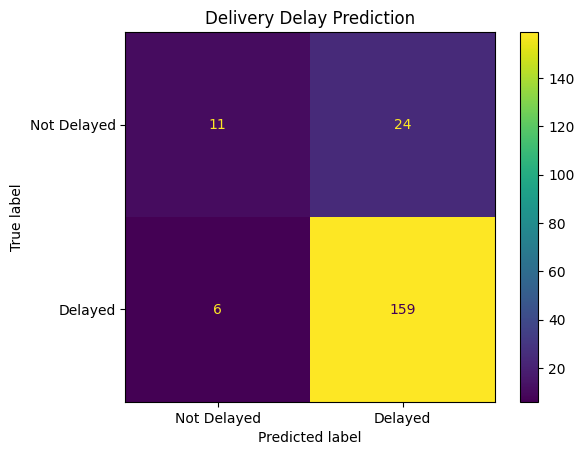

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_pipeline = None

# Train the selected model again and retain its pipeline
best_estimator = models[best_model_name]

best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_estimator)
])

best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Not Delayed", "Delayed"]
)

plt.title("Delivery Delay Prediction")
plt.show()

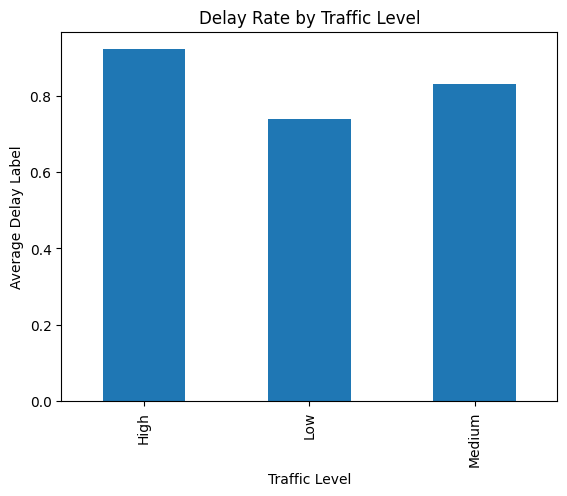

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

delay_rate = df.groupby("Traffic_Level")[
    "Delivery_Delayed"
].mean()

delay_rate.plot(kind="bar")
plt.title("Delay Rate by Traffic Level")
plt.ylabel("Average Delay Label")
plt.xlabel("Traffic Level")
plt.show()

In [27]:
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

search = GridSearchCV(
    rf_pipeline,
    params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

tuned_model = search.best_estimator_
pred = tuned_model.predict(X_test)

print("Best parameters:", search.best_params_)
print("Cross-validation F1:", round(search.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Test Precision:", round(
    precision_score(y_test, pred, zero_division=0), 4
))
print("Test Recall:", round(
    recall_score(y_test, pred, zero_division=0), 4
))
print("Test F1:", round(
    f1_score(y_test, pred, zero_division=0), 4
))

print(classification_report(
    y_test, pred, zero_division=0
))

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 100}
Cross-validation F1: 0.9078
Test Accuracy: 0.84
Test Precision: 0.8715
Test Recall: 0.9455
Test F1: 0.907
              precision    recall  f1-score   support

           0       0.57      0.34      0.43        35
           1       0.87      0.95      0.91       165

    accuracy                           0.84       200
   macro avg       0.72      0.64      0.67       200
weighted avg       0.82      0.84      0.82       200



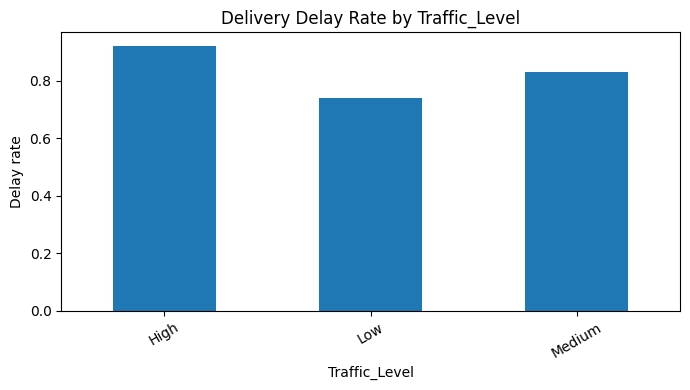

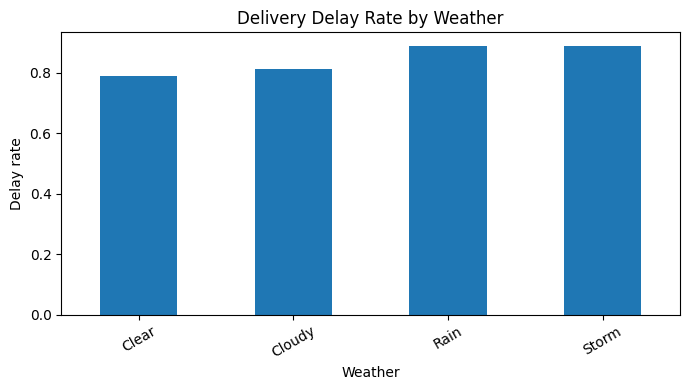

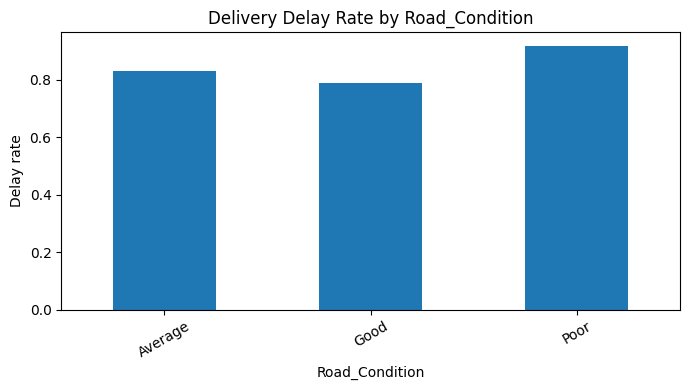

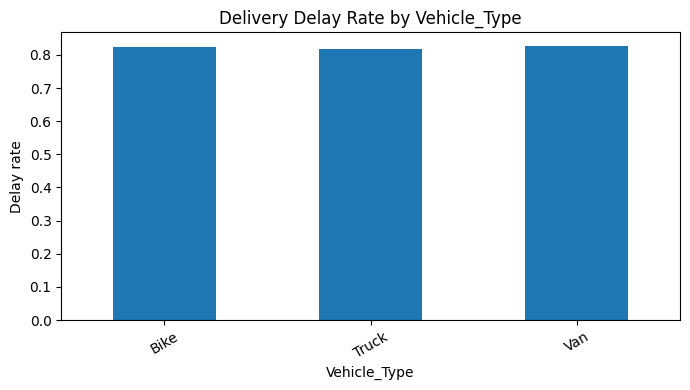

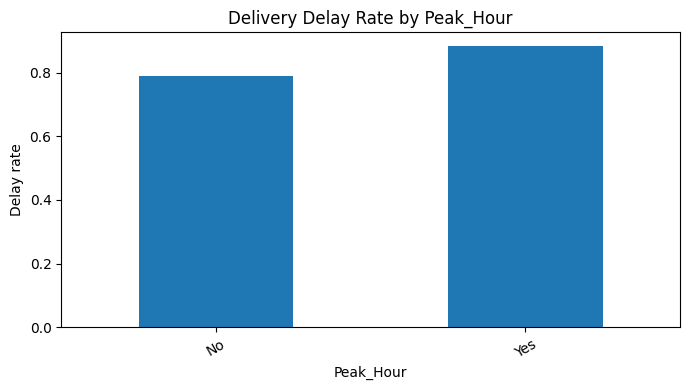

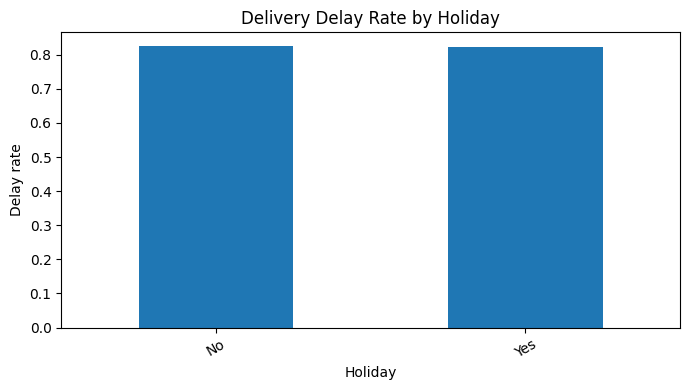

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

factors = [
    "Traffic_Level",
    "Weather",
    "Road_Condition",
    "Vehicle_Type",
    "Peak_Hour",
    "Holiday"
]

for col in factors:
    if col in df.columns:
        delay_rates = df.groupby(col)["Delivery_Delayed"].mean()

        delay_rates.plot(kind="bar", figsize=(7, 4))
        plt.title(f"Delivery Delay Rate by {col}")
        plt.ylabel("Delay rate")
        plt.xlabel(col)
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()